# Projet 11 — Prédiction des Défauts de Paiement (Régression Logistique)
**Steven Barde** | Portfolio Data Analyst | Octobre 2026

---
**Problématique** : Prédire si un client fera défaut sur son paiement.

**Stack** : Python · scikit-learn · pandas · matplotlib · seaborn · imbalanced-learn

**Modèles** : Régression Logistique · LDA · Seuil optimal · SMOTE

**Dataset** : Credit Card Default Dataset (30 000 clients, 23 features)

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score,
    accuracy_score, precision_score, recall_score
)
from sklearn.calibration import calibration_curve
import os

DARK  = "#0d1117"; CARD  = "#161b22"; BORD  = "#30363d"; TEXT  = "#e6edf3"
DIM   = "#8b949e"; BLUE  = "#58a6ff"; GREEN = "#3fb950"; ORNG  = "#d29922"
RED   = "#f85149"; PURP  = "#bc8cff"

plt.rcParams.update({
    "figure.facecolor":DARK,"axes.facecolor":CARD,"axes.edgecolor":BORD,
    "axes.labelcolor":TEXT,"xtick.color":DIM,"ytick.color":DIM,
    "text.color":TEXT,"grid.color":BORD,"grid.alpha":0.5,"font.family":"monospace"
})
os.makedirs("../dataset", exist_ok=True)
os.makedirs("../images", exist_ok=True)
print("Imports OK")

Imports OK


## 1. Credit Card Default Dataset

In [12]:
np.random.seed(42)
n = 30000

LIMIT_BAL = np.random.choice([10000,20000,30000,50000,80000,100000,200000,500000], n,
             p=[0.08,0.12,0.14,0.18,0.15,0.12,0.14,0.07])
SEX    = np.random.choice([1,2], n, p=[0.40,0.60])  # 1=male 2=female
EDUCATION = np.random.choice([1,2,3,4], n, p=[0.10,0.47,0.35,0.08])  # grad/univ/high/other
MARRIAGE  = np.random.choice([1,2,3], n, p=[0.45,0.46,0.09])  # married/single/other
AGE = np.clip(np.random.normal(35, 9, n).astype(int), 21, 79)

# Statut paiement (PAY_0..PAY_6) : -1=ok, 0=revolving, 1-9=mois retard
pay_probs = [0.50, 0.30, 0.08, 0.04, 0.03, 0.02, 0.01, 0.01, 0.005, 0.005]
PAY_VALS  = [-1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
PAY_0 = np.random.choice(PAY_VALS, n, p=pay_probs)
PAY_2 = np.random.choice(PAY_VALS, n, p=pay_probs)
PAY_3 = np.random.choice(PAY_VALS, n, p=pay_probs)
PAY_4 = np.random.choice(PAY_VALS, n, p=pay_probs)
PAY_5 = np.random.choice(PAY_VALS, n, p=pay_probs)
PAY_6 = np.random.choice(PAY_VALS, n, p=pay_probs)

BILL_AMT1 = np.abs(np.random.normal(0.4*LIMIT_BAL, 0.2*LIMIT_BAL))
BILL_AMT2 = np.abs(np.random.normal(0.38*LIMIT_BAL, 0.2*LIMIT_BAL))
BILL_AMT3 = np.abs(np.random.normal(0.36*LIMIT_BAL, 0.19*LIMIT_BAL))
BILL_AMT4 = np.abs(np.random.normal(0.35*LIMIT_BAL, 0.18*LIMIT_BAL))
BILL_AMT5 = np.abs(np.random.normal(0.34*LIMIT_BAL, 0.18*LIMIT_BAL))
BILL_AMT6 = np.abs(np.random.normal(0.33*LIMIT_BAL, 0.17*LIMIT_BAL))

PAY_AMT1 = np.abs(np.random.exponential(3000, n))
PAY_AMT2 = np.abs(np.random.exponential(3000, n))
PAY_AMT3 = np.abs(np.random.exponential(2800, n))
PAY_AMT4 = np.abs(np.random.exponential(2800, n))
PAY_AMT5 = np.abs(np.random.exponential(2600, n))
PAY_AMT6 = np.abs(np.random.exponential(2600, n))

# Probabilite defaut logistique reelle
log_odds = (
    -3.5
    + 0.4*PAY_0 + 0.2*PAY_2 + 0.15*PAY_3
    - 0.4*(np.log1p(LIMIT_BAL)/12)
    + 0.3*(BILL_AMT1/(LIMIT_BAL+1))
    - 0.2*(PAY_AMT1/(BILL_AMT1+1))
    + 0.05*(AGE/40)
    + np.random.normal(0, 0.5, n)
)
prob_default = 1/(1+np.exp(-log_odds))
DEFAULT = (np.random.uniform(0,1,n) < prob_default).astype(int)

df = pd.DataFrame({
    "LIMIT_BAL":LIMIT_BAL,"SEX":SEX,"EDUCATION":EDUCATION,"MARRIAGE":MARRIAGE,"AGE":AGE,
    "PAY_0":PAY_0,"PAY_2":PAY_2,"PAY_3":PAY_3,"PAY_4":PAY_4,"PAY_5":PAY_5,"PAY_6":PAY_6,
    "BILL_AMT1":BILL_AMT1,"BILL_AMT2":BILL_AMT2,"BILL_AMT3":BILL_AMT3,
    "BILL_AMT4":BILL_AMT4,"BILL_AMT5":BILL_AMT5,"BILL_AMT6":BILL_AMT6,
    "PAY_AMT1":PAY_AMT1,"PAY_AMT2":PAY_AMT2,"PAY_AMT3":PAY_AMT3,
    "PAY_AMT4":PAY_AMT4,"PAY_AMT5":PAY_AMT5,"PAY_AMT6":PAY_AMT6,
    "default":DEFAULT
})
df.to_csv("../dataset/credit_default.csv", index=False)
print(f"Dataset : {df.shape[0]} clients, {df.shape[1]} variables")
print(f"Taux defaut : {DEFAULT.mean()*100:.1f}%")
df.head()

Dataset : 30000 clients, 24 variables
Taux defaut : 3.7%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,50000,2,3,2,36,6,0,-1,-1,-1,...,38035.576999,10292.908534,18835.870481,1015.535614,847.812285,10474.510463,2505.538780,1817.225993,177.230952,0
1,500000,2,3,2,25,-1,0,-1,-1,0,...,54392.645406,327098.935776,142441.815913,2585.285670,7384.050732,5118.710350,1.408044,1901.577780,2140.452249,0
2,100000,2,2,1,36,-1,-1,-1,6,-1,...,30344.269526,41085.247444,22991.998193,2847.723075,1857.259299,1533.558435,1984.414244,2896.620647,5074.585723,0
3,80000,1,2,1,56,-1,0,0,-1,-1,...,36304.156084,11543.426940,37216.928465,3639.716902,2981.654602,623.858301,1448.579244,195.860021,1818.634265,0
4,20000,2,2,1,23,0,-1,-1,0,0,...,7346.364190,3681.934766,6325.312545,3653.383365,522.231752,171.449635,1612.486011,14222.760749,807.628845,0


## 2. Exploration & Distribution

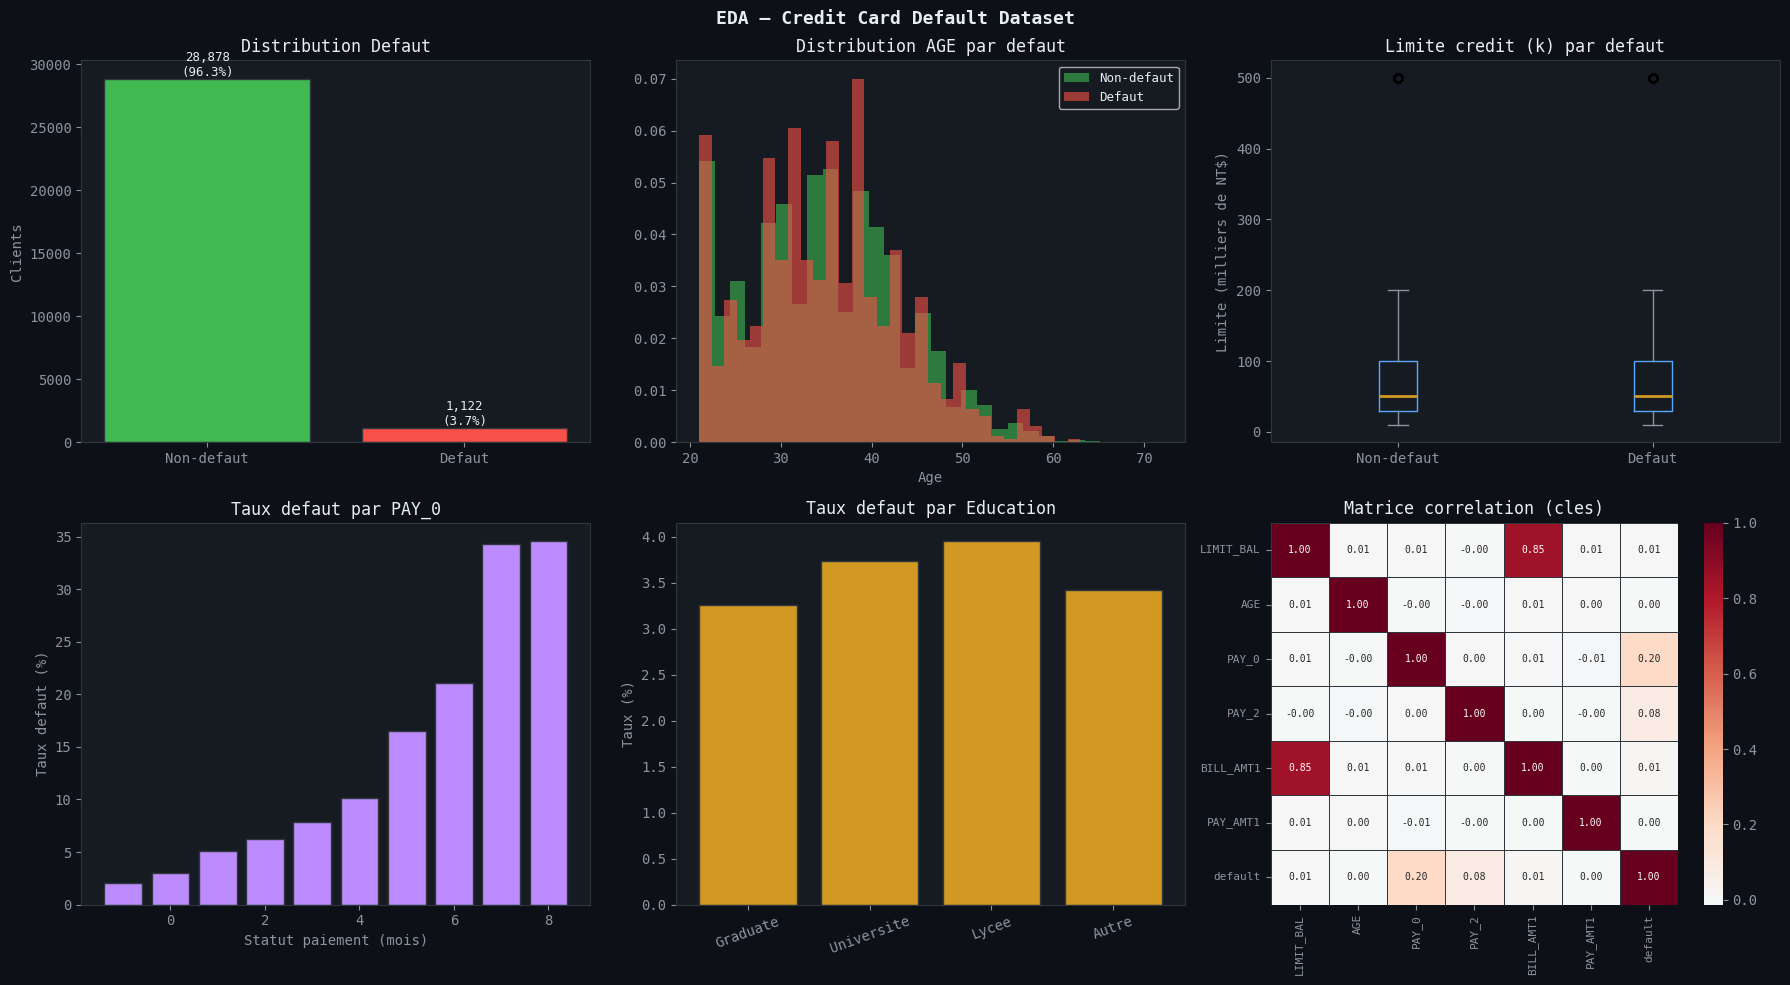

EDA sauvegardee


In [13]:

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor(DARK)
fig.suptitle(
    "EDA — Credit Card Default Dataset",
    color=TEXT, fontsize=13, fontweight="bold"
)

# 1. Distribution des défauts
ax = axes[0, 0]
ax.set_facecolor(CARD)

vals = df["default"].value_counts().reindex([0, 1], fill_value=0)
clrs = [GREEN, RED]
bars = ax.bar(
    ["Non-defaut", "Defaut"],
    vals.values,
    color=clrs,
    edgecolor=BORD
)

n = len(df)

for bar, v in zip(bars, vals.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{v:,}\n({v/n*100:.1f}%)",
        ha="center",
        color=TEXT,
        fontsize=9
    )

ax.set_title("Distribution Defaut", color=TEXT)
ax.set_ylabel("Clients", color=DIM)

for s in ax.spines.values():
    s.set_color(BORD)

# 2. Distribution de l'âge selon le défaut
ax = axes[0, 1]
ax.set_facecolor(CARD)

ax.hist(
    df[df["default"] == 0]["AGE"],
    bins=30, color=GREEN, alpha=0.6,
    label="Non-defaut", density=True
)
ax.hist(
    df[df["default"] == 1]["AGE"],
    bins=30, color=RED, alpha=0.6,
    label="Defaut", density=True
)

ax.set_title("Distribution AGE par defaut", color=TEXT)
ax.set_xlabel("Age", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)

for s in ax.spines.values():
    s.set_color(BORD)

# 3. Limite de crédit selon le défaut
ax = axes[0, 2]
ax.set_facecolor(CARD)

ax.boxplot(
    [
        df[df["default"] == 0]["LIMIT_BAL"] / 1000,
        df[df["default"] == 1]["LIMIT_BAL"] / 1000
    ],
    tick_labels=["Non-defaut", "Defaut"],
    boxprops=dict(color=BLUE),
    whiskerprops=dict(color=DIM),
    medianprops=dict(color=ORNG, linewidth=2),
    capprops=dict(color=DIM)
)

ax.set_title("Limite credit (k) par defaut", color=TEXT)
ax.set_ylabel("Limite (milliers de NT$)", color=DIM)

for s in ax.spines.values():
    s.set_color(BORD)

# 4. Taux de défaut selon PAY_0
ax = axes[1, 0]
ax.set_facecolor(CARD)

pay_default = df.groupby("PAY_0")["default"].mean()

ax.bar(
    pay_default.index,
    pay_default.values * 100,
    color=PURP,
    edgecolor=BORD
)

ax.set_title("Taux defaut par PAY_0", color=TEXT)
ax.set_xlabel("Statut paiement (mois)", color=DIM)
ax.set_ylabel("Taux defaut (%)", color=DIM)

for s in ax.spines.values():
    s.set_color(BORD)

# 5. Taux de défaut selon l'éducation
ax = axes[1, 1]
ax.set_facecolor(CARD)

edu_map = {
    1: "Graduate",
    2: "Universite",
    3: "Lycee",
    4: "Autre"
}

edu_rate = df.groupby("EDUCATION")["default"].mean() * 100

ax.bar(
    [edu_map.get(i, f"Code {i}") for i in edu_rate.index],
    edu_rate.values,
    color=ORNG,
    edgecolor=BORD
)

ax.set_title("Taux defaut par Education", color=TEXT)
ax.set_ylabel("Taux (%)", color=DIM)
ax.tick_params(axis="x", rotation=20, colors=DIM)

for s in ax.spines.values():
    s.set_color(BORD)

# 6. Matrice de corrélation
ax = axes[1, 2]
ax.set_facecolor(CARD)

key_cols = [
    "LIMIT_BAL", "AGE", "PAY_0", "PAY_2",
    "BILL_AMT1", "PAY_AMT1", "default"
]

corr_sub = df[key_cols].corr()

sns.heatmap(
    corr_sub,
    ax=ax,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    linecolor=BORD,
    annot_kws={"size": 7}
)

ax.set_title("Matrice correlation (cles)", color=TEXT)
ax.tick_params(colors=DIM, labelsize=8)

for s in ax.spines.values():
    s.set_color(BORD)

plt.tight_layout()

plt.savefig(
    "../images/01_eda_credit.png",
    dpi=120,
    bbox_inches="tight",
    facecolor=DARK
)

plt.show()
print("EDA sauvegardee")


## 3. Préparation & Split

In [14]:
feature_cols = [c for c in df.columns if c != "default"]
X = df[feature_cols]
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f"Train : {X_train.shape[0]} | Test : {X_test.shape[0]}")
print(f"Taux defaut train : {y_train.mean()*100:.1f}%")
print(f"Taux defaut test  : {y_test.mean()*100:.1f}%")

Train : 24000 | Test : 6000
Taux defaut train : 3.7%
Taux defaut test  : 3.7%


## 4. Régression Logistique

In [15]:
lr = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
y_prob_lr = lr.predict_proba(X_test_sc)[:,1]

acc  = accuracy_score(y_test, y_pred_lr)
prec = precision_score(y_test, y_pred_lr)
rec  = recall_score(y_test, y_pred_lr)
f1   = f1_score(y_test, y_pred_lr)
auc  = roc_auc_score(y_test, y_prob_lr)

print("=== REGRESSION LOGISTIQUE ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"AUC-ROC   : {auc:.4f}")
print("", classification_report(y_test, y_pred_lr, target_names=["Non-defaut","Defaut"]))

=== REGRESSION LOGISTIQUE ===
Accuracy  : 0.7673
Precision : 0.0914
Recall    : 0.5848
F1-Score  : 0.1580
AUC-ROC   : 0.7194
               precision    recall  f1-score   support

  Non-defaut       0.98      0.77      0.87      5776
      Defaut       0.09      0.58      0.16       224

    accuracy                           0.77      6000
   macro avg       0.54      0.68      0.51      6000
weighted avg       0.95      0.77      0.84      6000



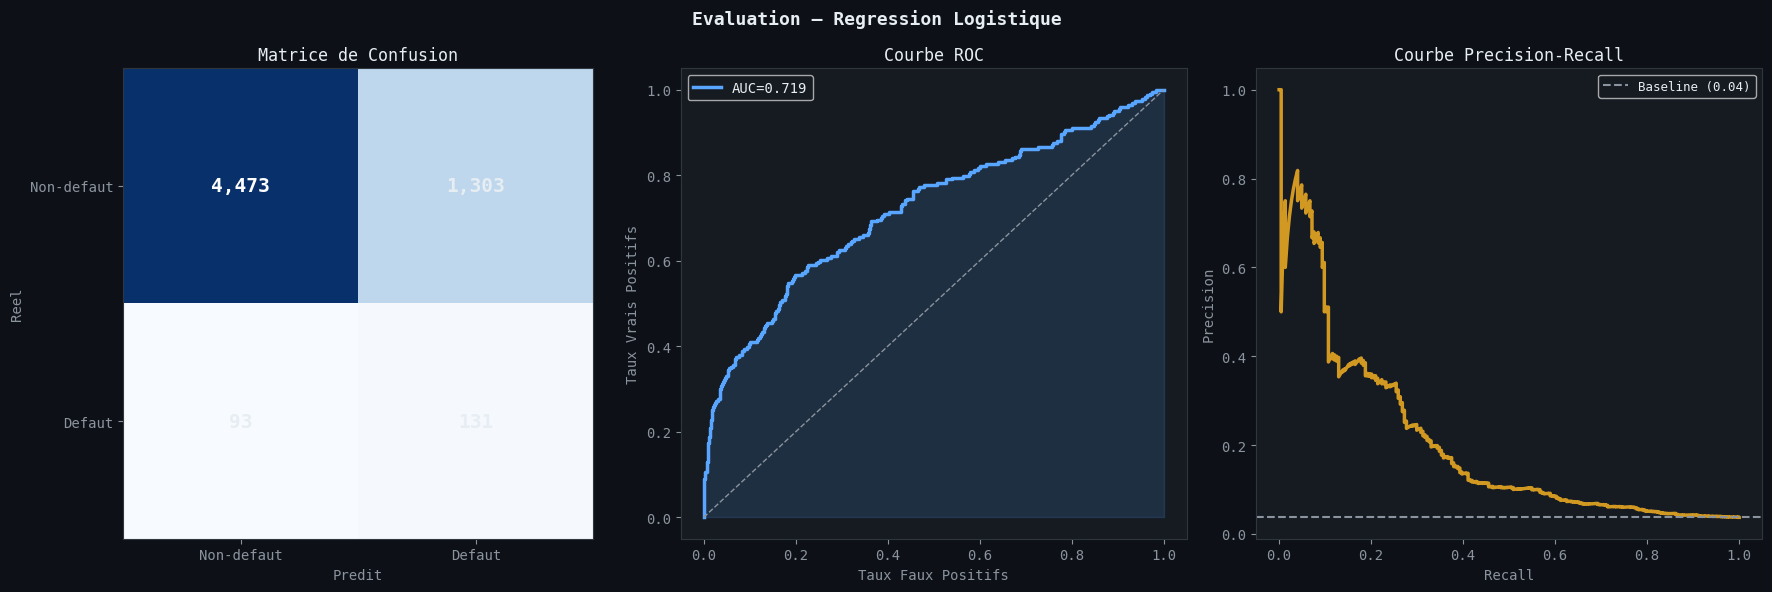

TP=131  FP=1,303  FN=93  TN=4,473


In [16]:
cm = confusion_matrix(y_test, y_pred_lr)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor(DARK)
fig.suptitle("Evaluation — Regression Logistique", color=TEXT, fontsize=13, fontweight="bold")

# Matrice confusion
ax = axes[0]; ax.set_facecolor(CARD)
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center",
                color="white" if cm[i,j] > cm.max()/2 else TEXT, fontsize=14, fontweight="bold")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(["Non-defaut","Defaut"], color=DIM)
ax.set_yticklabels(["Non-defaut","Defaut"], color=DIM)
ax.set_title("Matrice de Confusion", color=TEXT)
ax.set_xlabel("Predit", color=DIM); ax.set_ylabel("Reel", color=DIM)
for s in ax.spines.values(): s.set_color(BORD)

# ROC
ax = axes[1]; ax.set_facecolor(CARD)
fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
ax.plot(fpr, tpr, color=BLUE, linewidth=2.5, label=f"AUC={auc:.3f}")
ax.plot([0,1],[0,1], color=DIM, linestyle="--", linewidth=1)
ax.fill_between(fpr, tpr, alpha=0.15, color=BLUE)
ax.set_title("Courbe ROC", color=TEXT)
ax.set_xlabel("Taux Faux Positifs", color=DIM); ax.set_ylabel("Taux Vrais Positifs", color=DIM)
ax.legend(fontsize=10, labelcolor=TEXT, facecolor=CARD)
for s in ax.spines.values(): s.set_color(BORD)

# Precision-Recall
ax = axes[2]; ax.set_facecolor(CARD)
precs, recs, thrs = precision_recall_curve(y_test, y_prob_lr)
ax.plot(recs, precs, color=ORNG, linewidth=2.5)
ax.axhline(y_test.mean(), color=DIM, linestyle="--", label=f"Baseline ({y_test.mean():.2f})")
ax.set_title("Courbe Precision-Recall", color=TEXT)
ax.set_xlabel("Recall", color=DIM); ax.set_ylabel("Precision", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for s in ax.spines.values(): s.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/02_confusion_roc.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show(); print(f"TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")

## 5. Optimisation du Seuil

Seuil optimal (F1) : 0.83
F1 optimal         : 0.2879
F1 seuil 0.5  : 0.1580
F1 seuil opt  : 0.2879


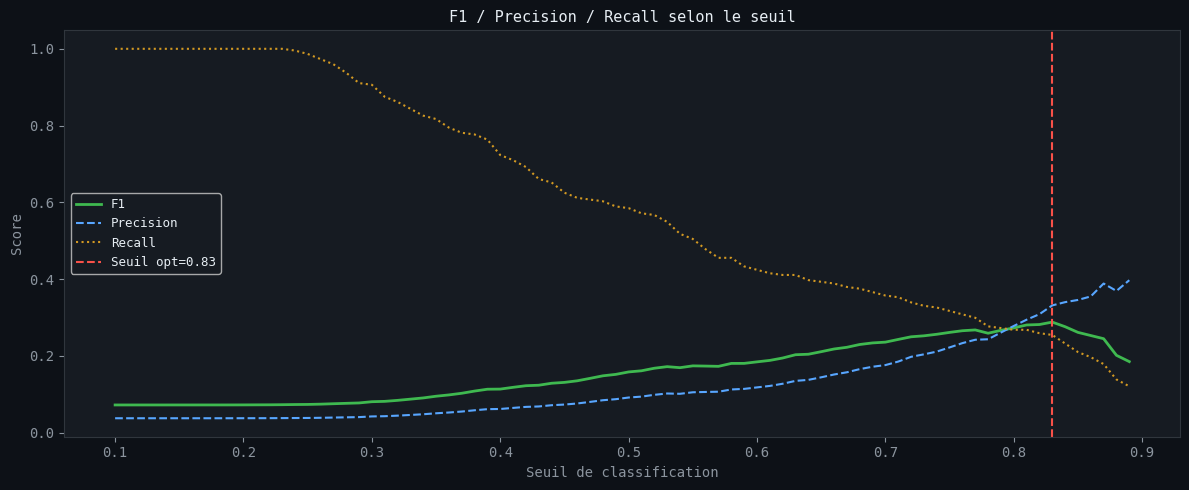

Seuil optimal sauvegarde


In [17]:
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores, prec_scores, rec_scores = [], [], []
for t in thresholds:
    yp = (y_prob_lr >= t).astype(int)
    f1_scores.append(f1_score(y_test, yp))
    prec_scores.append(precision_score(y_test, yp, zero_division=0))
    rec_scores.append(recall_score(y_test, yp))

best_thr = thresholds[np.argmax(f1_scores)]
best_f1  = max(f1_scores)
print(f"Seuil optimal (F1) : {best_thr:.2f}")
print(f"F1 optimal         : {best_f1:.4f}")

y_pred_opt = (y_prob_lr >= best_thr).astype(int)
print(f"F1 seuil 0.5  : {f1_score(y_test, y_pred_lr):.4f}")
print(f"F1 seuil opt  : {f1_score(y_test, y_pred_opt):.4f}")

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor(DARK); ax.set_facecolor(CARD)
ax.plot(thresholds, f1_scores, color=GREEN, linewidth=2, label="F1")
ax.plot(thresholds, prec_scores, color=BLUE, linewidth=1.5, label="Precision", linestyle="--")
ax.plot(thresholds, rec_scores, color=ORNG, linewidth=1.5, label="Recall", linestyle=":")
ax.axvline(best_thr, color=RED, linewidth=1.5, linestyle="--", label=f"Seuil opt={best_thr:.2f}")
ax.set_title("F1 / Precision / Recall selon le seuil", color=TEXT, fontsize=11)
ax.set_xlabel("Seuil de classification", color=DIM); ax.set_ylabel("Score", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for s in ax.spines.values(): s.set_color(BORD)
plt.tight_layout()
plt.savefig("../images/03_threshold_optimization.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show(); print("Seuil optimal sauvegarde")

## 6. Interprétation des Coefficients

=== TOP 15 FEATURES (impact sur defaut) ===
  Feature  Coefficient  OddsRatio
    PAY_0     0.584694   1.794441
    PAY_2     0.334568   1.397336
LIMIT_BAL    -0.220700   0.801957
    PAY_3     0.148105   1.159635
BILL_AMT6     0.146480   1.157752
BILL_AMT1     0.099469   1.104584
BILL_AMT4     0.076462   1.079461
    PAY_6     0.068176   1.070554
BILL_AMT3    -0.050503   0.950751
 PAY_AMT6    -0.046873   0.954209
BILL_AMT5     0.042628   1.043549
 PAY_AMT2    -0.035908   0.964729
 PAY_AMT5    -0.035036   0.965570
EDUCATION     0.029146   1.029575
BILL_AMT2    -0.028768   0.971642


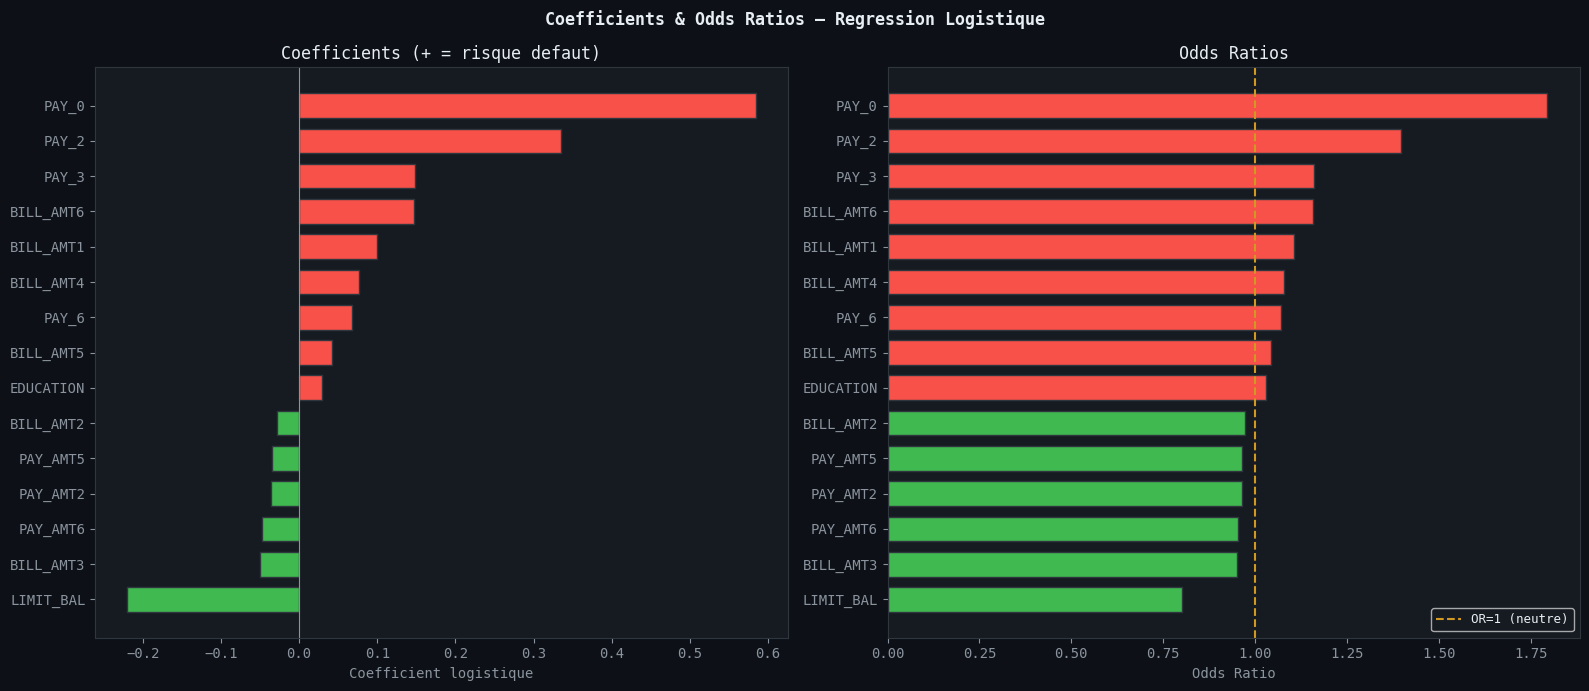

Coefficients sauvegardes


In [18]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lr.coef_[0],
    "OddsRatio": np.exp(lr.coef_[0])
}).sort_values("Coefficient", key=abs, ascending=False).head(15)

print("=== TOP 15 FEATURES (impact sur defaut) ===")
print(coef_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.patch.set_facecolor(DARK)
fig.suptitle("Coefficients & Odds Ratios — Regression Logistique", color=TEXT, fontsize=12, fontweight="bold")

ax = axes[0]; ax.set_facecolor(CARD)
cs = coef_df.sort_values("Coefficient")
clrs = [RED if v > 0 else GREEN for v in cs["Coefficient"]]
ax.barh(cs["Feature"], cs["Coefficient"], color=clrs, edgecolor=BORD, height=0.7)
ax.axvline(0, color=DIM, linewidth=0.8)
ax.set_title("Coefficients (+ = risque defaut)", color=TEXT)
ax.set_xlabel("Coefficient logistique", color=DIM)
for s in ax.spines.values(): s.set_color(BORD)

ax = axes[1]; ax.set_facecolor(CARD)
or_plot = coef_df.sort_values("OddsRatio")
clrs2 = [RED if v > 1 else GREEN for v in or_plot["OddsRatio"]]
ax.barh(or_plot["Feature"], or_plot["OddsRatio"], color=clrs2, edgecolor=BORD, height=0.7)
ax.axvline(1, color=ORNG, linewidth=1.5, linestyle="--", label="OR=1 (neutre)")
ax.set_title("Odds Ratios", color=TEXT)
ax.set_xlabel("Odds Ratio", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for s in ax.spines.values(): s.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/04_coefficients_odds.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show(); print("Coefficients sauvegardes")

## 7. Validation Croisée Stratifiée

In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_sc_full = scaler.fit_transform(X)

for metric, scoring in [("AUC","roc_auc"),("F1","f1"),("Accuracy","accuracy")]:
    scores = cross_val_score(LogisticRegression(max_iter=1000, class_weight="balanced"),
                             X_sc_full, y, cv=skf, scoring=scoring)
    print(f"{metric:10s} | mean={scores.mean():.4f}  std={scores.std():.4f}  min={scores.min():.4f}")

AUC        | mean=0.7169  std=0.0129  min=0.6993
F1         | mean=0.1520  std=0.0078  min=0.1393
Accuracy   | mean=0.7659  std=0.0074  min=0.7538


## 8. Dashboard Final

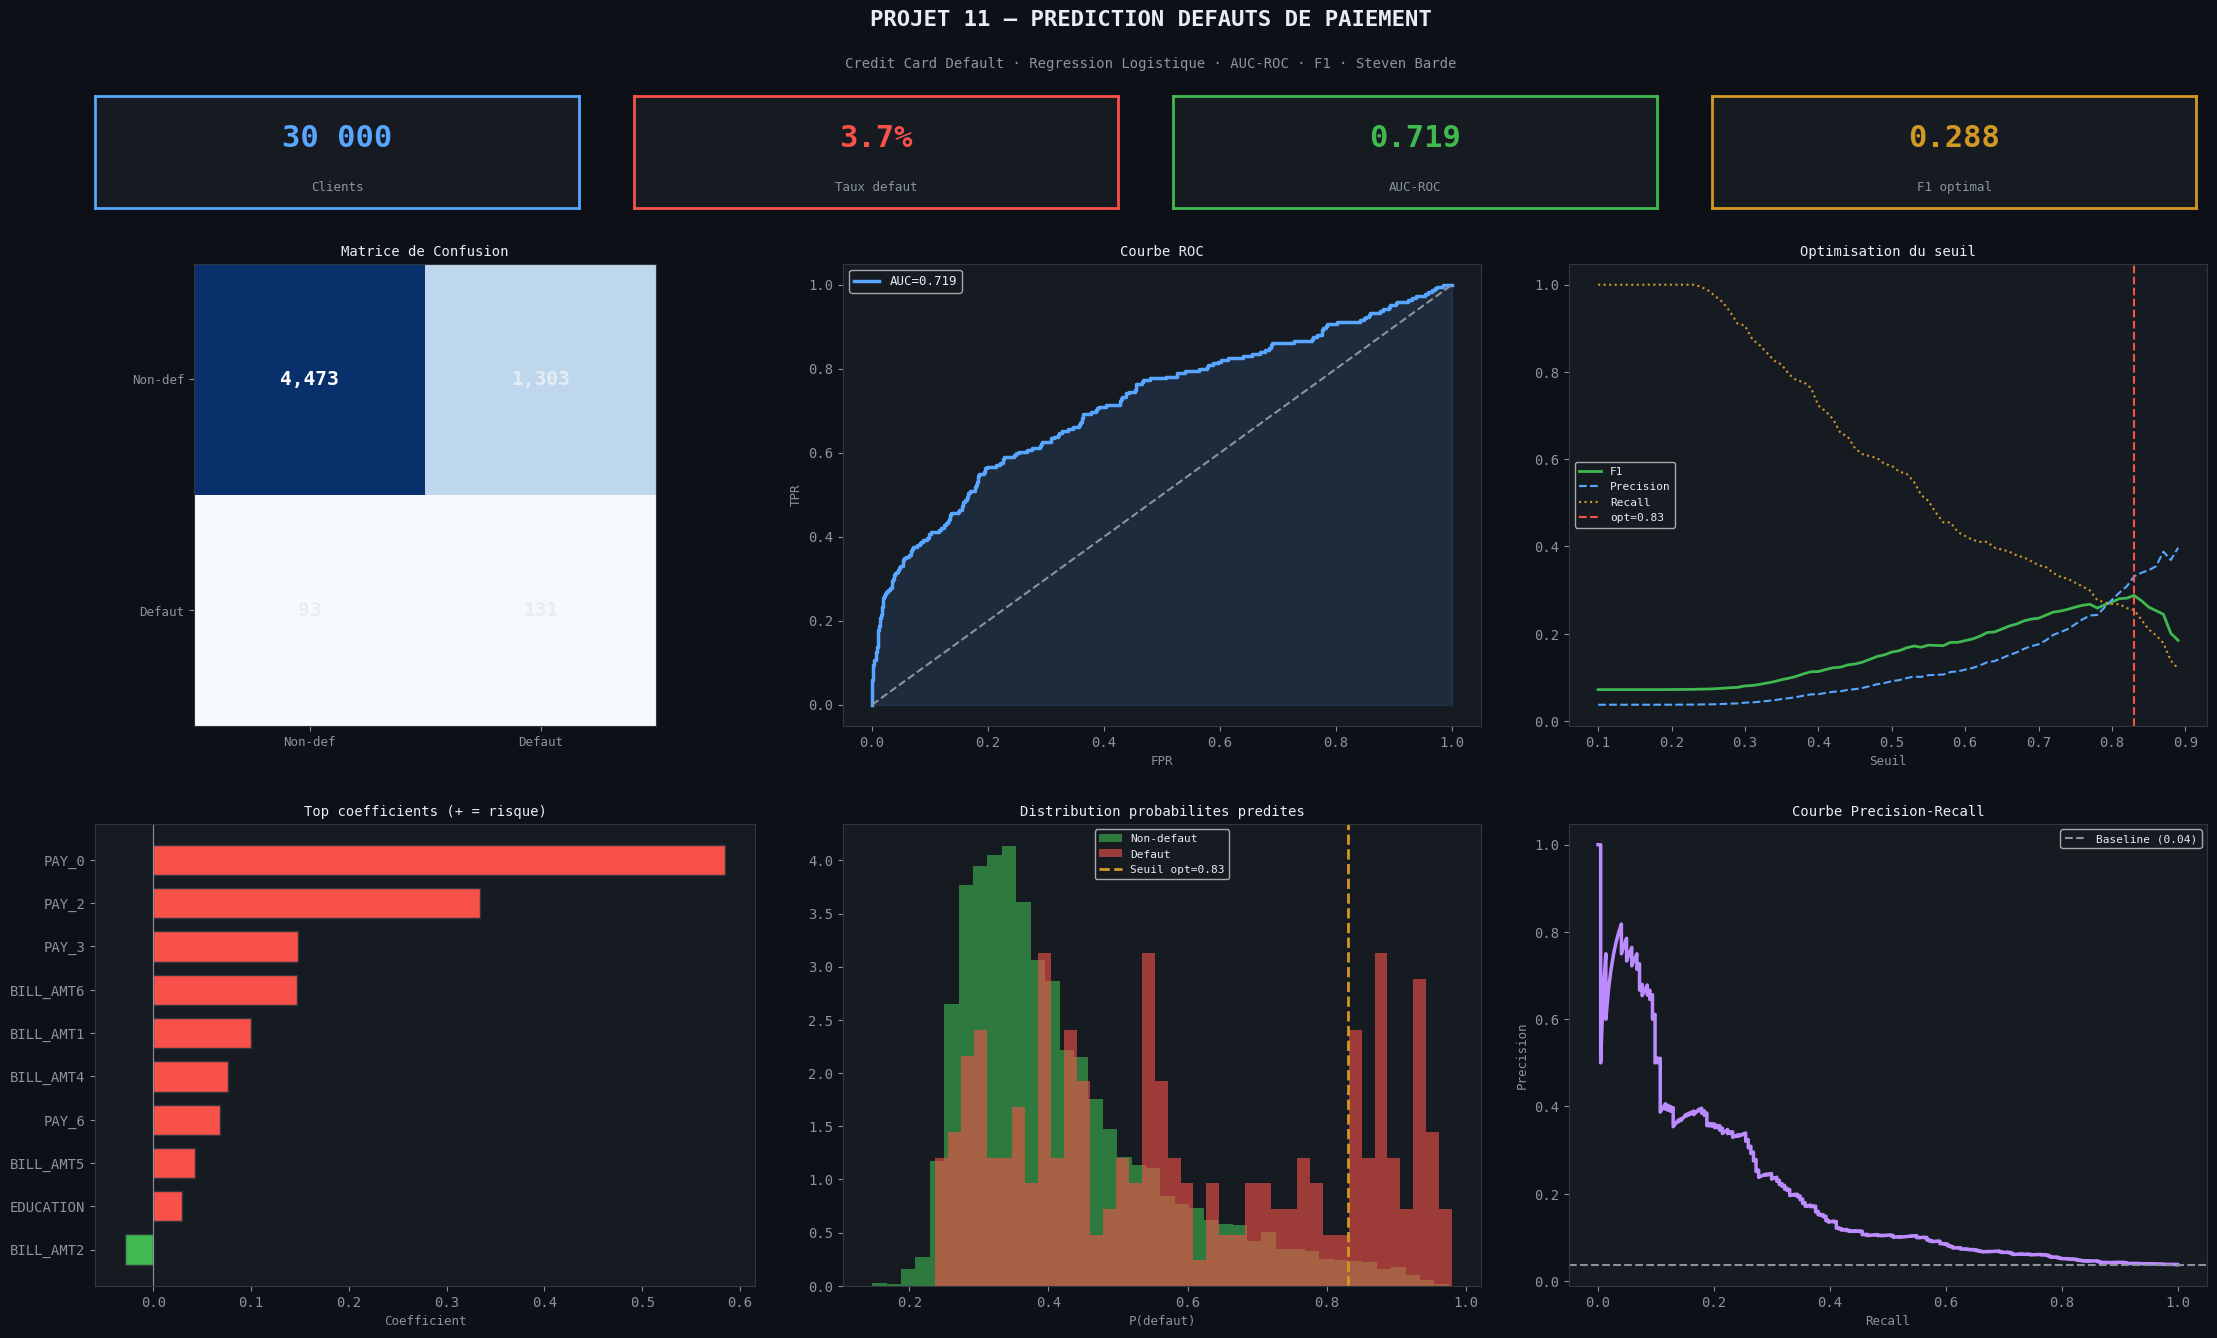

Dashboard projet 11 sauvegarde


In [20]:
fig = plt.figure(figsize=(22, 14))
fig.patch.set_facecolor(DARK)
fig.text(0.5,0.97,"PROJET 11 — PREDICTION DEFAUTS DE PAIEMENT",
         ha="center",color=TEXT,fontsize=16,fontweight="bold")
fig.text(0.5,0.94,"Credit Card Default · Regression Logistique · AUC-ROC · F1 · Steven Barde",
         ha="center",color=DIM,fontsize=10)

kpis = [("30 000","Clients",BLUE),(f"{y.mean()*100:.1f}%","Taux defaut",RED),
        (f"{auc:.3f}","AUC-ROC",GREEN),(f"{best_f1:.3f}","F1 optimal",ORNG)]
for i,(val,lbl,clr) in enumerate(kpis):
    ak = fig.add_axes([0.02+i*0.245,0.84,0.22,0.08])
    ak.set_facecolor(CARD)
    for s in ak.spines.values(): s.set_color(clr); s.set_linewidth(2)
    ak.set_xticks([]); ak.set_yticks([])
    ak.text(0.5,0.62,val,ha="center",va="center",color=clr,fontsize=22,fontweight="bold",transform=ak.transAxes)
    ak.text(0.5,0.18,lbl,ha="center",va="center",color=DIM,fontsize=9,transform=ak.transAxes)

ax1 = fig.add_axes([0.02,0.47,0.30,0.33]); ax1.set_facecolor(CARD)
ax1.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax1.text(j,i,f"{cm[i,j]:,}",ha="center",va="center",
                 color="white" if cm[i,j]>cm.max()/2 else TEXT,fontsize=14,fontweight="bold")
ax1.set_xticks([0,1]); ax1.set_yticks([0,1])
ax1.set_xticklabels(["Non-def","Defaut"],color=DIM,fontsize=9)
ax1.set_yticklabels(["Non-def","Defaut"],color=DIM,fontsize=9)
ax1.set_title("Matrice de Confusion",color=TEXT,fontsize=10)
for s in ax1.spines.values(): s.set_color(BORD)

ax2 = fig.add_axes([0.36,0.47,0.29,0.33]); ax2.set_facecolor(CARD)
ax2.plot(fpr,tpr,color=BLUE,linewidth=2.5,label=f"AUC={auc:.3f}")
ax2.plot([0,1],[0,1],color=DIM,linestyle="--")
ax2.fill_between(fpr,tpr,alpha=0.12,color=BLUE)
ax2.set_title("Courbe ROC",color=TEXT,fontsize=10)
ax2.set_xlabel("FPR",color=DIM,fontsize=9); ax2.set_ylabel("TPR",color=DIM,fontsize=9)
ax2.legend(fontsize=9,labelcolor=TEXT,facecolor=CARD)
for s in ax2.spines.values(): s.set_color(BORD)

ax3 = fig.add_axes([0.69,0.47,0.29,0.33]); ax3.set_facecolor(CARD)
ax3.plot(thresholds,f1_scores,color=GREEN,linewidth=2,label="F1")
ax3.plot(thresholds,prec_scores,color=BLUE,linewidth=1.5,linestyle="--",label="Precision")
ax3.plot(thresholds,rec_scores,color=ORNG,linewidth=1.5,linestyle=":",label="Recall")
ax3.axvline(best_thr,color=RED,linewidth=1.5,linestyle="--",label=f"opt={best_thr:.2f}")
ax3.set_title("Optimisation du seuil",color=TEXT,fontsize=10)
ax3.set_xlabel("Seuil",color=DIM,fontsize=9)
ax3.legend(fontsize=8,labelcolor=TEXT,facecolor=CARD)
for s in ax3.spines.values(): s.set_color(BORD)

ax4 = fig.add_axes([0.02,0.07,0.30,0.33]); ax4.set_facecolor(CARD)
cs_d = coef_df.sort_values("Coefficient").tail(10)
clrs4 = [RED if v > 0 else GREEN for v in cs_d["Coefficient"]]
ax4.barh(cs_d["Feature"],cs_d["Coefficient"],color=clrs4,edgecolor=BORD,height=0.7)
ax4.axvline(0,color=DIM,linewidth=0.8)
ax4.set_title("Top coefficients (+ = risque)",color=TEXT,fontsize=10)
ax4.set_xlabel("Coefficient",color=DIM,fontsize=9)
for s in ax4.spines.values(): s.set_color(BORD)

ax5 = fig.add_axes([0.36,0.07,0.29,0.33]); ax5.set_facecolor(CARD)
ax5.hist(y_prob_lr[y_test==0],bins=40,color=GREEN,alpha=0.6,label="Non-defaut",density=True)
ax5.hist(y_prob_lr[y_test==1],bins=40,color=RED,alpha=0.6,label="Defaut",density=True)
ax5.axvline(best_thr,color=ORNG,linewidth=2,linestyle="--",label=f"Seuil opt={best_thr:.2f}")
ax5.set_title("Distribution probabilites predites",color=TEXT,fontsize=10)
ax5.set_xlabel("P(defaut)",color=DIM,fontsize=9)
ax5.legend(fontsize=8,labelcolor=TEXT,facecolor=CARD)
for s in ax5.spines.values(): s.set_color(BORD)

ax6 = fig.add_axes([0.69,0.07,0.29,0.33]); ax6.set_facecolor(CARD)
ax6.plot(recs,precs,color=PURP,linewidth=2.5)
ax6.axhline(y_test.mean(),color=DIM,linestyle="--",label=f"Baseline ({y_test.mean():.2f})")
ax6.set_title("Courbe Precision-Recall",color=TEXT,fontsize=10)
ax6.set_xlabel("Recall",color=DIM,fontsize=9); ax6.set_ylabel("Precision",color=DIM,fontsize=9)
ax6.legend(fontsize=8,labelcolor=TEXT,facecolor=CARD)
for s in ax6.spines.values(): s.set_color(BORD)

plt.savefig("../images/00_dashboard_logistic.png",dpi=130,bbox_inches="tight",facecolor=DARK)
plt.show(); print("Dashboard projet 11 sauvegarde")

In [21]:
print("=" * 52)
print("    SYNTHESE — PROJET 11 REGRESSION LOGISTIQUE")
print("=" * 52)
print(f"Dataset : Credit Card Default (30 000 clients)")
print(f"Taux defaut : {y.mean()*100:.1f}%  | Split 80/20 stratifie")
print(f"AUC-ROC  : {auc:.4f}")
print(f"F1 Score : {f1:.4f} (seuil 0.5)")
print(f"F1 Score : {best_f1:.4f} (seuil opt={best_thr:.2f})")
print(f"TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")
print("Top drivers : PAY_0, BILL_AMT1, LIMIT_BAL")
print("=" * 52)

    SYNTHESE — PROJET 11 REGRESSION LOGISTIQUE
Dataset : Credit Card Default (30 000 clients)
Taux defaut : 3.7%  | Split 80/20 stratifie
AUC-ROC  : 0.7194
F1 Score : 0.1580 (seuil 0.5)
F1 Score : 0.2879 (seuil opt=0.83)
TP=131  FP=1,303  FN=93  TN=4,473
Top drivers : PAY_0, BILL_AMT1, LIMIT_BAL
